# PCA 與 Kernel PCA 

> 這份教材會以 PCA (Principal Component Analysis，主成分分析) 與 Kernel PCA (核主成分分析) 為核心，從降維的直覺、參數設定，到 Python 實作、模型評估與視覺化。

這兩種方法都屬於非監督式學習，主要任務是將高維度資料轉換成較少的特徵，而不是直接預測答案。

## 什麼是降維 (Dimensionality Reduction)？

![](./assets/降維.png)

## PCA (Principal Component Analysis)

PCA 中文稱為主成分分析。它是一種線性降維方法，主要透過尋找資料變異最大的方向，將原本的高維度資料投影到較低維度的空間。

白話來說：「PCA 會尋找最能呈現資料分散情況的方向，讓我們用較少的座標描述資料。」

### PCA 的直覺

假設我們收集學生的身高與體重：

| 學生 | 身高 (cm) | 體重 (kg) |
| -- | ------- | ------- |
| A  | 155     | 48      |
| B  | 160     | 52      |
| C  | 170     | 65      |
| D  | 175     | 70      |
| E  | 180     | 78      |

身高與體重可能呈現正相關。當學生身高增加，體重也可能增加，因此散佈圖上的點可能形成一條斜向延伸的資料群。PCA 會尋找這群資料最主要的延伸方向。

![](./assets/PCA.png)

PCA 會產生新的主成分：

- PC1 (第一主成分)：資料變異最大的方向。
- PC2 (第二主成分)：與 PC1 垂直，並且在剩餘方向中具有最大的變異。
- PC3 (第三主成分)：與前兩個主成分正交，繼續保留剩餘變異。

如果 PC1 已經保留了大部分變異，我們就可能只使用 PC1 來描述原始資料。

### PCA 的運作流程

```
原始高維度資料
        ↓
資料標準化 (StandardScaler)
        ↓
尋找資料變異最大的方向
        ↓
計算 Principal Components
        ↓
選擇保留的主成分數量
        ↓
轉換成低維度資料
```

## PCA 的 Explained Variance

PCA 有一個非常重要的概念：Explained Variance (解釋變異量)。

它用來衡量每個主成分保留了多少資料變異。

假設原始資料有 8 個 Features，經過 PCA 後得到：

| 主成分 | Explained Variance Ratio |
| --- | ------------------------ |
| PC1 | 45%                      |
| PC2 | 25%                      |
| PC3 | 15%                      |
| PC4 | 8%                       |
| PC5 | 4%                       |
| PC6 | 2%                       |
| PC7 | 0.8%                     |
| PC8 | 0.2%                     |


如果保留 PC1 與 PC2：

$$ 45\% + 25\% = 70\% $$

代表兩個主成分保留了原始資料總變異的 70%。

如果保留 PC1、PC2、PC3：

$$ 45\% + 25\% + 15\% = 85\% $$

代表三個主成分保留了 85% 的總變異。

![](./assets/Explained%20Variance.png)


## PCA 為什麼需要 StandardScaler？

PCA 會根據資料變異尋找主成分，因此不同 Features 的數值尺度會直接影響結果。

假設我們有兩個 Features：

| Feature | 數值範圍              |
| ------- | ----------------- |
| 年齡      | 18～65             |
| 年收入     | 300,000～2,000,000 |

收入的數值尺度遠大於年齡。如果直接執行 PCA，收入可能因為數值尺度較大，而主導主成分方向。這不代表收入一定比較重要。

因此，通常會先使用 StandardScaler。

$$ \boxed{ \text{原始資料} \rightarrow \text{StandardScaler} \rightarrow \text{PCA} } $$

```python
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline


### 建立 PCA Pipeline
model = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(
        n_components=2,
        random_state=42
    ))
])
```

這裡的 StandardScaler 會讓各特徵以訓練資料的平均數與標準差進行轉換，使不同單位的 Features 更容易比較。

不過，PCA 並不是任何情況都必須標準化。如果所有特徵本來就在相同尺度，而且原始變異大小具有實際意義，也可以依分析目的決定是否標準化。

## Kernel PCA (核主成分分析)

PCA 主要尋找線性的主成分方向。但現實資料不一定呈現直線或橢圓形分布。例如資料可能形成：

- 同心圓。
- 月牙形。
- 彎曲的帶狀結構。
- 其他複雜的非線性分布。

這時候可以考慮 Kernel PCA。

### PCA 與 Kernel PCA 的差別

假設資料呈現兩個同心圓：
- 傳統 PCA 只能尋找線性投影方向。
- Kernel PCA 則利用 Kernel Function (核函數)，計算資料之間的非線性相似關係，讓資料在新的表示空間中可能更容易區分。

### Kernel PCA 的直覺

可以想像把一張有彎曲圖案的紙，透過另一種方式重新表示，讓原本複雜的結構變得更容易觀察。

Kernel PCA 不需要真的把每個資料點轉換到完整的高維空間，而是利用核函數計算資料之間的相似程度。

```text
原始非線性資料
        ↓
StandardScaler
        ↓
Kernel Function
        ↓
計算資料之間的相似關係
        ↓
Kernel PCA
        ↓
低維度特徵
```

要注意，Kernel PCA 並不保證所有非線性資料經過降維後都會變得容易分類。結果取決於資料結構、Kernel 類型及參數。

![](./assets/PCA_vs_Kernel_PCA.png)

## Kernel Function (核函數)

Kernel PCA 的核心參數是：`kernel="rbf"`。不同 Kernel 會讓模型以不同方式描述資料之間的關係。

| Kernel      | 說明          | 適用情況          |
| ----------- | ----------- | ------------- |
| `"linear"`  | 線性核函數       | 線性資料          |
| `"poly"`    | 多項式核函數      | 具有多項式型態的非線性關係 |
| `"rbf"`     | 徑向基底核函數     | 常見的非線性資料      |
| `"sigmoid"` | Sigmoid 核函數 | 特定非線性結構       |
| `"cosine"`  | 餘弦相似度核函數    | 關注向量方向相似性的資料  |

入門階段建議先使用：

```
kernel="rbf"
```

RBF 是 Kernel PCA 常見的選擇，但並不代表它對所有資料都是最佳設定。

### gamma 參數

RBF Kernel 中，`gamma` 用來控制資料點之間的相似程度，會隨距離增加而下降得多快。

| gamma | 常見效果                |
| ----- | ------------------- |
| 較小    | 相似程度隨距離下降較慢，變化較平滑   |
| 較大    | 相似程度隨距離下降較快，更強調局部關係 |

例如：`gamma=0.1`或`gamma=10.0`，gamma 太小或太大，都可能無法產生理想的降維結果。

### PCA 與 Kernel PCA 比較

| 比較項目                     | PCA         | Kernel PCA  |
| ------------------------ | ----------- | ----------- |
| 學習類型                     | 非監督式        | 非監督式        |
| 降維方式                     | 線性          | 可處理非線性      |
| 是否需要 Target              | 不需要         | 不需要         |
| 核函數                      | 不需要         | 需要選擇        |
| Explained Variance Ratio | 有           | 沒有相同意義的直接屬性 |
| 運算成本                     | 通常較低        | 大型資料可能較高    |
| 常見用途                     | 壓縮、去除冗餘、視覺化 | 非線性特徵轉換、視覺化 |

Kernel PCA 常需要建立與樣本數相關的 Kernel Matrix，因此當資料筆數非常大時，記憶體及計算成本可能明顯增加。

## 實作：使用 PCA 分析機械感測器資料

這個實作分成兩個部分：

降維分析： 將 8 個 Features 轉換成 PC1、PC2，觀察資料的分布。

分類模型： 將 PCA 加入 Logistic Regression Pipeline，評估降維後的分類表現。

### 實作資料集

為了讓學生真正看出 PCA 與 Kernel PCA 的差別，我準備了兩份不同的 CSV 資料集。

- 資料集 A(pca_machine_sensors.csv)：機械感測器資料。900 筆資料 · 8 個 Features · 3 種狀態
- 資料集 B(kernel_pca_circles.csv)：非線性同心圓資料。800 筆資料 · 2 個 Features · 2 種群組

### 資料集 A 欄位

| 欄位                   | 說明               |
| -------------------- | ---------------- |
| `sensor_temperature` | 模擬溫度特徵           |
| `sensor_pressure`    | 模擬壓力特徵           |
| `sensor_vibration`   | 模擬震動特徵           |
| `sensor_current`     | 模擬電流特徵           |
| `sensor_voltage`     | 模擬電壓特徵           |
| `sensor_flow`        | 模擬流量特徵           |
| `sensor_acoustic`    | 模擬聲音特徵           |
| `sensor_humidity`    | 模擬濕度特徵           |
| `machine_status`     | 模擬機台狀態類別 (0、1、2) |

> 這份資料適合用來練習：
> - StandardScaler。
> - PCA 降維。
> - Explained Variance Ratio。
> - PCA Scatter Plot。
> - PCA + Logistic Regression。
> - 比較降維前後的分類效果。

### 資料集 B 欄位

| 欄位          | 說明            |
| ----------- | ------------- |
| `feature_x` | 二維座標 X        |
| `feature_y` | 二維座標 Y        |
| `group`     | 內圈或外圈類別 (0、1) |

> 這份資料適合用來比較 Linear PCA 與 RBF Kernel PCA 對非線性結構的處理差異。

### 讀取資料集

In [2]:
import pandas as pd
import numpy as np


### 讀取資料集
df = pd.read_csv("./data/pca_machine_sensors.csv")


### 查看前 10 筆資料
print(df.head(10))


### 查看資料基本資訊
print(df.info())


### 查看數值統計
print(df.describe())


### 查看資料形狀
print("資料形狀：", df.shape)

   sensor_temperature  sensor_pressure  sensor_vibration  sensor_current  \
0           -3.882078         0.318171          2.132103       -2.433202   
1            4.067003         1.864266          1.346029        3.846358   
2            1.379741         2.303961          1.718889        1.472098   
3            5.300643         2.994872         -2.524424        2.191888   
4           -0.541500         2.569921          2.643577        0.593688   
5            4.527409         0.284387         -2.368567        1.437744   
6           -2.084548         3.036877          1.668402       -0.974701   
7            4.467422         1.047920         -1.653136        1.624637   
8           -3.847703         3.580292          0.332665       -1.962293   
9            1.855143         1.766708         -0.060441        1.384319   

   sensor_voltage  sensor_flow  sensor_acoustic  sensor_humidity  \
0       -0.941686     2.352028        -1.507861        -2.298126   
1       -5.712531     3.634

### 探索資料 (EDA)

PCA 特別適合用來觀察多個 Features 是否存在重複資訊。例如：
- 電流與電壓可能存在關聯。
- 溫度與壓力可能一起變化。
- 不同感測器可能測量到相近的潛在狀態。

In [3]:
### 查看缺失值
print(df.isnull().sum())


### 查看重複資料數量
print("重複資料：", df.duplicated().sum())


### 查看不同機台狀態的資料數量
print(df["machine_status"].value_counts())


### 查看特徵之間的相關係數
print(df.corr(numeric_only=True))

sensor_temperature    0
sensor_pressure       0
sensor_vibration      0
sensor_current        0
sensor_voltage        0
sensor_flow           0
sensor_acoustic       0
sensor_humidity       0
machine_status        0
dtype: int64
重複資料： 0
machine_status
0    301
1    301
2    298
Name: count, dtype: int64
                    sensor_temperature  sensor_pressure  sensor_vibration  \
sensor_temperature            1.000000         0.166508         -0.671292   
sensor_pressure               0.166508         1.000000          0.002205   
sensor_vibration             -0.671292         0.002205          1.000000   
sensor_current                0.816072         0.201739         -0.230231   
sensor_voltage               -0.734030         0.110894          0.278594   
sensor_flow                  -0.642341        -0.098024          0.333152   
sensor_acoustic              -0.285887         0.228228         -0.338778   
sensor_humidity               0.921287        -0.032688         -0.420125   
ma

### 資料清理

In [4]:
### 移除重複資料
df = df.drop_duplicates().copy()


### 移除 Target 缺失的資料
df = df.dropna(subset=["machine_status"])


### 重設索引
df = df.reset_index(drop=True)


### 確認資料
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   sensor_temperature  900 non-null    float64
 1   sensor_pressure     900 non-null    float64
 2   sensor_vibration    900 non-null    float64
 3   sensor_current      900 non-null    float64
 4   sensor_voltage      900 non-null    float64
 5   sensor_flow         900 non-null    float64
 6   sensor_acoustic     900 non-null    float64
 7   sensor_humidity     900 non-null    float64
 8   machine_status      900 non-null    int64  
dtypes: float64(8), int64(1)
memory usage: 63.4 KB
None


### 選擇 Features 與 Target

這裡需要釐清：PCA 本身不需要 y。

我們保留 machine_status，是為了後續使用 Logistic Regression 分類，以及在 Scatter Plot 中標示不同類別。

PCA 不會使用 Target 來決定主成分方向。

In [5]:
### 選擇 Features
X = df.drop(columns=["machine_status"]).copy()


### 選擇 Target
y = df["machine_status"].copy()


### 查看資料
print("Features：", X.shape)
print("Target：", y.shape)

Features： (900, 8)
Target： (900,)


### Train / Validation / Test Split

In [6]:
from sklearn.model_selection import train_test_split


### 先保留 20% Test
X_development, X_test, y_development, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


### 再從剩餘 80% 切出 20% Validation
X_train, X_valid, y_train, y_valid = train_test_split(
    X_development,
    y_development,
    test_size=0.25,
    random_state=42,
    stratify=y_development
)


### 查看資料數量
print("Train：", X_train.shape)
print("Validation：", X_valid.shape)
print("Test：", X_test.shape)

Train： (540, 8)
Validation： (180, 8)
Test： (180, 8)


### 建立 PCA 模型

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA


### 建立 PCA Pipeline
pca_model = Pipeline([
    ("imputer", SimpleImputer(
        strategy="median" # 使用 Train 的中位數填補缺失值
    )),
    ("scaler", StandardScaler()), # 將 Features 標準化
    ("pca", PCA(
        n_components=2, # 將 8 個 Features 降成 2 個主成分
        svd_solver="full", # 使用完整 SVD 計算
        random_state=42
    ))
])


### 使用 Train 訓練 PCA
pca_model.fit(X_train)


### 將資料轉換成 PCA 特徵
X_train_pca = pca_model.transform(X_train)
X_valid_pca = pca_model.transform(X_valid)
X_test_pca = pca_model.transform(X_test)


### 查看降維後的形狀
print("Train：", X_train_pca.shape)
print("Validation：", X_valid_pca.shape)
print("Test：", X_test_pca.shape)
# 原本的 Features 有 8 個。
# 執行後，每筆資料只剩下 2 個主成分。

Train： (540, 2)
Validation： (180, 2)
Test： (180, 2)


### 查看 Explained Variance Ratio

In [8]:
### 取得 PCA 模型
pca = pca_model.named_steps["pca"]


### 查看每個主成分的解釋變異比例
print("Explained Variance Ratio：")
print(pca.explained_variance_ratio_)


### 計算累積解釋變異比例
print("Cumulative Explained Variance：")
print(np.cumsum(pca.explained_variance_ratio_))

Explained Variance Ratio：
[0.53402525 0.20740325]
Cumulative Explained Variance：
[0.53402525 0.7414285 ]


### 查看主成分組成

components_ 代表每個主成分在標準化特徵空間中的方向係數。

例如某個特徵在 PC1 的係數絕對值較大，代表它在 PC1 的線性組合中具有較大的權重。

但係數不是因果關係，也不應直接視為對 Target 的重要性。

In [10]:
### 將主成分係數整理成 DataFrame
components_df = pd.DataFrame(
    pca.components_.T,
    index=X.columns,
    columns=["PC1", "PC2"]
)


### 查看主成分係數
display(components_df)

,PC1,PC2
sensor_temperature,0.456901,0.248856
sensor_pressure,0.014508,0.446113
sensor_vibration,-0.222560,-0.537198
sensor_current,0.397754,0.095056
sensor_voltage,-0.408692,0.233674
sensor_flow,-0.335275,-0.049948
sensor_acoustic,-0.268609,0.616077
sensor_humidity,0.481352,-0.069189


### PCA 視覺化

#### PCA Scatter Plot

這張圖可以用來觀察三種機台狀態在 PC1、PC2 空間中的分布。

但如果三種顏色重疊，不代表 PCA 執行失敗。

因為 PCA 尋找的是最大變異方向，不是最大分類差異。

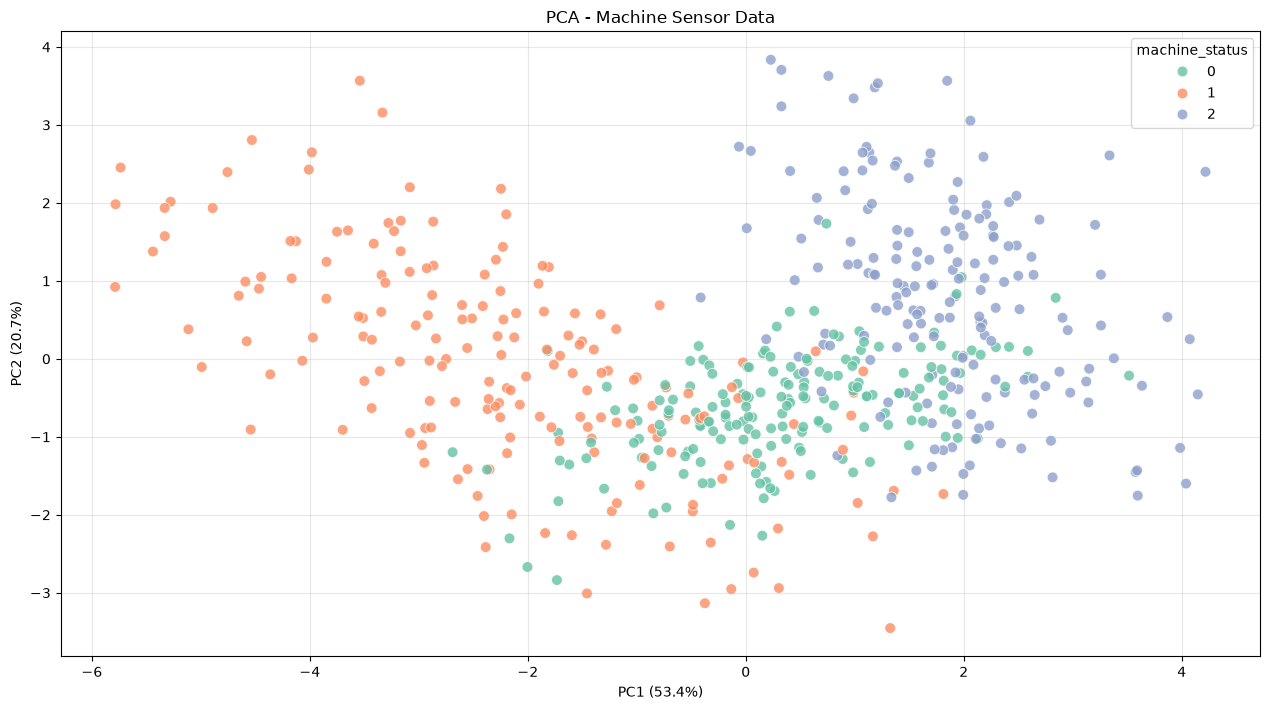

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns


### 將降維結果轉成 DataFrame
pca_df = pd.DataFrame(
    X_train_pca,
    columns=["PC1", "PC2"]
)


### 加入真實類別
pca_df["machine_status"] = y_train.to_numpy()


### 建立圖表
plt.figure(figsize=(12.8, 7.2))


### 繪製 Scatter Plot
sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="machine_status",
    palette="Set2",
    s=60,
    alpha=0.8
)


### 設定圖表資訊
plt.title("PCA - Machine Sensor Data")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
plt.grid(alpha=0.3)


### 顯示圖表
plt.tight_layout()
plt.show()

## 實作：PCA + Logistic Regression 分類模型
PCA 本身不會預測機台狀態。

如果希望完成「訓練模型 → 預測 → 評估」，可以把 PCA 當成分類模型的前處理。

流程：
$$
\boxed{
\text{原始 Features}
\rightarrow
\text{StandardScaler}
\rightarrow
\text{PCA}
\rightarrow
\text{Logistic Regression}
\rightarrow
\text{預測類別}
}
$$

### 建立分類 Pipeline

In [13]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn import set_config

### 關閉 scikit-learn 模型的 HTML 視覺化顯示
set_config(display="text")

### 建立 PCA + Logistic Regression
model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("pca", PCA(
        n_components=2,
        svd_solver="full"
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])


### 訓練模型
model.fit(X_train, y_train)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('pca', PCA(n_components=2, svd_solver='full')),
                ('classifier',
                 LogisticRegression(max_iter=1000, random_state=42))])

### 使用模型預測

In [15]:
### 預測 Validation 類別
y_valid_pred = model.predict(X_valid)


### 查看前 10 筆預測
print("預測類別：")
print(y_valid_pred[:10])


### 查看前 10 筆真實答案
print("真實類別：")
print(y_valid.to_numpy()[:10])

預測類別：
[2 1 2 2 1 0 1 2 0 1]
真實類別：
[0 1 0 2 1 2 1 2 0 1]


### 評估模型表現

這裡的 Accuracy、Precision、Recall、F1 都是在評估 Logistic Regression 分類模型，不是 PCA 本身的預測準確率。

In [16]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)


### 計算 Accuracy
accuracy = accuracy_score(y_valid, y_valid_pred)


### 顯示評估結果
print("Validation Accuracy：", accuracy)

print("\nClassification Report：")
print(classification_report(
    y_valid,
    y_valid_pred,
    zero_division=0
))

print("\nConfusion Matrix：")
print(confusion_matrix(y_valid, y_valid_pred))

Validation Accuracy： 0.7444444444444445

Classification Report：
              precision    recall  f1-score   support

           0       0.64      0.53      0.58        60
           1       0.78      0.78      0.78        60
           2       0.79      0.92      0.85        60

    accuracy                           0.74       180
   macro avg       0.74      0.74      0.74       180
weighted avg       0.74      0.74      0.74       180


Confusion Matrix：
[[32 13 15]
 [13 47  0]
 [ 5  0 55]]


## 實作：Kernel PCA 

這次使用同心圓資料集(""./data/kernel_pca_circles.csv)，比較 Linear PCA 與 RBF Kernel PCA。

因為資料原本只有 2 個 Features，所以本實驗會將它轉換成 1 個 Component，觀察一維特徵是否能區分內圈與外圈。

### 讀取資料集

In [19]:
import pandas as pd


### 讀取非線性資料
df_circle = pd.read_csv("./data/kernel_pca_circles.csv")


### 查看資料
print(df_circle.head(10))


### 查看資料資訊
print(df_circle.info())


### 查看統計資訊
print(df_circle.describe())

   feature_x  feature_y  group
0  -0.090978  -0.314026      1
1  -0.210529  -0.359522      1
2   0.541531   0.763340      0
3  -0.212166   0.220170      1
4   0.646572   0.863210      0
5  -0.380111  -0.098393      1
6   0.653449  -0.765579      0
7   0.097744   0.398716      1
8   0.246021  -0.246032      1
9   0.203845   0.108545      1
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   feature_x  800 non-null    float64
 1   feature_y  800 non-null    float64
 2   group      800 non-null    int64  
dtypes: float64(2), int64(1)
memory usage: 18.9 KB
None
        feature_x   feature_y       group
count  800.000000  800.000000  800.000000
mean     0.002716    0.003864    0.500000
std      0.532310    0.538847    0.500313
min     -1.177683   -1.203384    0.000000
25%     -0.325332   -0.329340    0.000000
50%      0.011788   -0.017075    0.500000
75%  

### 選擇 Features 與 Target

In [21]:
### 選擇 Features
X = df_circle[["feature_x", "feature_y"]].copy()


### 選擇 Target (僅用於分類與視覺化)
y = df_circle["group"].copy()

### Train / Validation / Test Split

In [22]:
from sklearn.model_selection import train_test_split


### 切分 Test 20%
X_development, X_test, y_development, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


### 切分 Train 60%、Validation 20%
X_train, X_valid, y_train, y_valid = train_test_split(
    X_development,
    y_development,
    test_size=0.25,
    random_state=42,
    stratify=y_development
)

### 建立 Kernel PCA

In [24]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import KernelPCA


### 建立 Kernel PCA
kpca_model = Pipeline([
    ("scaler", StandardScaler()),
    ("kpca", KernelPCA(
        n_components=1, # 轉換成 1 個新特徵
        kernel="rbf",   # 使用 RBF Kernel
        gamma=1.0,      # 控制 RBF 的距離敏感程度
        eigen_solver="auto",
        random_state=42
    ))
])


### 訓練 Kernel PCA
kpca_model.fit(X_train)


### 轉換資料
X_train_kpca = kpca_model.transform(X_train)
X_valid_kpca = kpca_model.transform(X_valid)


### 查看資料形狀
print("Train：", X_train_kpca.shape)
print("Validation：", X_valid_kpca.shape)

Train： (480, 1)
Validation： (160, 1)


### 比較 PCA 與 Kernel PCA

In [25]:
from sklearn.decomposition import PCA


### 建立一般 PCA
pca_model = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=1))
])


### 訓練 PCA
pca_model.fit(X_train)


### 轉換資料
X_train_pca = pca_model.transform(X_train)

### 覺化比較
這次我們將三張圖放在同一個 Figure 中，讓學生觀察不同方法的差異。

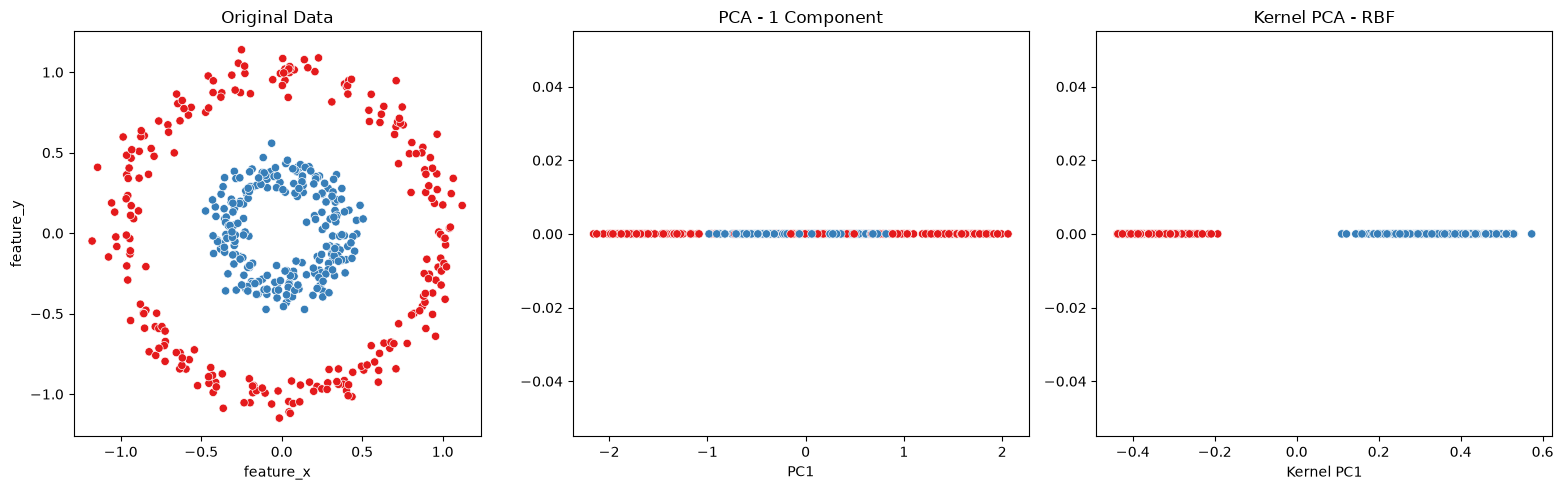

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


### 建立圖表
fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 5)
)


### 原始資料
sns.scatterplot(
    x=X_train["feature_x"],
    y=X_train["feature_y"],
    hue=y_train,
    palette="Set1",
    ax=axes[0],
    legend=False
)

axes[0].set_title("Original Data")
axes[0].set_aspect("equal", adjustable="box")


### PCA 降維結果
sns.scatterplot(
    x=X_train_pca[:, 0],
    y=np.zeros(len(X_train_pca)),
    hue=y_train,
    palette="Set1",
    ax=axes[1],
    legend=False
)

axes[1].set_title("PCA - 1 Component")
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("")


### Kernel PCA 降維結果
sns.scatterplot(
    x=X_train_kpca[:, 0],
    y=np.zeros(len(X_train_kpca)),
    hue=y_train,
    palette="Set1",
    ax=axes[2],
    legend=False
)

axes[2].set_title("Kernel PCA - RBF")
axes[2].set_xlabel("Kernel PC1")
axes[2].set_ylabel("")


### 顯示圖表
plt.tight_layout()
plt.show()

#### 中間：PCA - 1 Component

PCA 會尋找資料變異最大的方向，然後將資料投影到該方向。

但這份資料的兩群是內外圓結構，無論 PCA 選擇哪個直線方向，都可能讓內圈與外圈的資料投影到相同位置。

例如：
- 內圈藍色資料投影到 PC1 = 0.5。
- 外圈紅色資料也可能投影到 PC1 = 0.5。

因此，PCA 雖然成功將二維資料降成一維，卻沒有保留足夠的資訊來區分內外兩群。

#### 右邊：Kernel PCA - RBF

Kernel PCA 使用核函數 (Kernel Function)，這裡使用的是 RBF。

RBF 能夠捕捉資料中的非線性關係，使 Kernel PCA 不必像一般 PCA 一樣，只沿著原始空間中的直線方向進行投影。

對於內外圓資料，RBF Kernel 可以利用資料點之間的非線性相似程度，讓內圈與外圈在新的主成分上呈現不同數值。

因此，Kernel PCA 成功將二維資料降成一維，同時保留了原本內外圓的分群差異。

> 當資料具有非線性結構時，Kernel PCA 可能比一般 PCA 更適合保留特定的資料差異。
